
# Explainable AI for Early Sepsis Detection

## Project objective
Predict sepsis risk from hourly ICU observations using XGBoost and LSTM, compare their performance, and explain model predictions.

## Workflow
1. Dataset verification and preprocessing
2. Patient-level train/validation/test split
3. Temporal feature engineering
4. XGBoost training and threshold selection
5. LSTM sequence modelling
6. Held-out test evaluation
7. SHAP explainability
8. Save and verify model artifacts

**Scope:** Academic research prototype, not a clinically validated diagnostic system.


In [ ]:

# CELL 1 — Permanent setup
# PURPOSE: Configure paths and load existing evaluation results.
# This cell does not retrain models or modify source data.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

PROJECT_DIR = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
PROCESSED_DIR = PROJECT_DIR / "processed"

# Verify that the expected saved artifacts exist.
required_files = [
    MODELS_DIR / "xgboost_sepsis.json",
    MODELS_DIR / "xgboost_tuned_candidate.json",
    MODELS_DIR / "lstm_sepsis.keras",
    MODELS_DIR / "lstm_features.joblib",
    MODELS_DIR / "lstm_imputer.joblib",
    MODELS_DIR / "lstm_scaler.joblib",
    RESULTS_DIR / "final_model_comparison.csv",
    RESULTS_DIR / "xgboost_test_metrics.csv",
    RESULTS_DIR / "lstm_test_metrics.csv",
]

missing_files = [str(path) for path in required_files if not path.is_file()]

if missing_files:
    raise FileNotFoundError(
        "Required project artifacts are missing:\n" + "\n".join(missing_files)
    )

comparison = pd.read_csv(RESULTS_DIR / "final_model_comparison.csv")

print("Project folder:", PROJECT_DIR)
print("Saved model and result files: verified")
print("Model comparison:")
display(comparison.round(4))


Project folder: /content/drive/MyDrive/Early_Sepsis_AI_Clean
Saved model and result files: verified
Model comparison:


,Model,Threshold,PR-AUC,ROC-AUC,Recall,Precision,F1
0,XGBoost baseline,0.50,0.0909,0.8016,0.5756,0.0640,0.1152
1,XGBoost tuned,0.13,0.1003,0.8138,0.8845,0.0316,0.0610
2,LSTM,0.50,0.1067,0.8166,0.7991,0.0562,0.1050


## 3. Dataset and Experimental Setup

- **Dataset:** PhysioNet/CinC Challenge 2019.
- **Task:** Predict sepsis from hourly ICU observations.
- **Splitting strategy:** Patient-level training, validation, and testing splits to reduce data leakage.
- **Feature engineering:** Previous-hour values and six-hour rolling averages.
- **Models:** XGBoost and LSTM.
- **Evaluation:** PR-AUC, ROC-AUC, recall, precision, and F1-score.
- **Explainability:** SHAP for XGBoost.

**Important:** This is a retrospective research prototype, not a clinically validated diagnostic system.

In [ ]:
# CELL 2 — Permanent dataset verification
# PURPOSE: Check batch filenames for gaps and duplicates.
# This cell only reads filenames; it does not modify data.

batch_numbers = []

unique_batches = set(batch_numbers)
max_batch = max(batch_numbers, default=0)

# Report full-dataset batches separately from the pilot file.
full_batches = [
    file for file in parquet_files
    if file.stem.startswith("batch_")
    and file.stem.split("_")[-1].isdigit()
]

pilot_files = [
    file for file in parquet_files
    if file.name == "pilot_batch.parquet"
]

print("Full-dataset batch files:", len(full_batches))
print("Pilot files kept separately:", len(pilot_files))
print("Total Parquet files:", len(parquet_files))

Full-dataset batch files: 404
Pilot files kept separately: 1
Total Parquet files: 405


In [ ]:
# CELL 3 — Permanent dataset structure verification
# PURPOSE: Inspect one full-data batch without loading the entire dataset.
# This cell only reads data and does not modify files or train models.

sample_file = full_batches[0]
sample_df = pd.read_parquet(sample_file)

print("Sample batch:", sample_file.name)
print("Rows:", len(sample_df))
print("Columns:", len(sample_df.columns))
print("\nColumn names:")
print(sample_df.columns.tolist())
print("\nFirst 5 rows:")
display(sample_df.head())

Sample batch: batch_0001.parquet
Rows: 3704
Columns: 42

Column names:
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'PatientID']

First 5 rows:


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,PatientID
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,0,training_setA_p000001
1,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,0,training_setA_p000001
2,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,0,training_setA_p000001
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,0,training_setA_p000001
4,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,0,training_setA_p000001


In [ ]:
# CELL 4 — Permanent dataset summary
# PURPOSE: Count rows, unique patients, and positive sepsis records.
# Reads full-data batches only; does not modify files or train models.

total_rows = 0
total_positive = 0
all_patient_ids = set()

for file in full_batches:
    df = pd.read_parquet(
        file, columns=["PatientID", "SepsisLabel"]
    )
    total_rows += len(df)
    total_positive += int(df["SepsisLabel"].sum())
    all_patient_ids.update(df["PatientID"].dropna().unique())

print("Full-data batches:", len(full_batches))
print("Total hourly records:", total_rows)
print("Unique patients:", len(all_patient_ids))
print("Positive sepsis records:", total_positive)
print("Positive record percentage:", round(
    100 * total_positive / total_rows, 3
), "%")

Full-data batches: 404
Total hourly records: 1552210
Unique patients: 40336
Positive sepsis records: 27916
Positive record percentage: 1.798 %


In [ ]:
# CELL 5 — Permanent split-file verification
# PURPOSE: Locate saved patient-level splits without recreating them.
# This cell only checks existing files.

print("Project directory:", PROJECT_DIR)

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file() and any(
        word in path.name.lower()
        for word in ["train", "valid", "test", "split"]
    ):
        print(path.relative_to(PROJECT_DIR))

Project directory: /content/drive/MyDrive/Early_Sepsis_AI_Clean
checkpoints/patient_split.json
processed/test_data/X_test.parquet
processed/test_data/y_test.parquet
processed/train_data/X_train.parquet
processed/train_data/y_train.parquet
results/lstm_test_metrics.csv
results/xgboost_test_metrics.csv
results/xgboost_validation_thresholds.csv


In [ ]:
# CELL 6 — Permanent patient-split inspection
# PURPOSE: Inspect the existing split definition without changing it.

split_path = PROJECT_DIR / "checkpoints" / "patient_split.json"

with open(split_path, "r") as f:
    split_data = json.load(f)

print("Split file:", split_path)
print("Stored keys:", list(split_data.keys()))

for key, value in split_data.items():
    if isinstance(value, list):
        print(f"{key}: {len(value)} entries")
    elif isinstance(value, dict):
        print(f"{key}: dictionary with {len(value)} keys")
    else:
        print(f"{key}: {value}")

Split file: /content/drive/MyDrive/Early_Sepsis_AI_Clean/checkpoints/patient_split.json
Stored keys: ['train', 'validation', 'test']
train: 28235 entries
validation: 6050 entries
test: 6051 entries


In [ ]:
# CELL 7 — Permanent split-integrity verification
# PURPOSE: Confirm patient IDs do not overlap between splits.
# This cell only reads the existing split file.

train_ids = set(split_data["train"])
val_ids = set(split_data["validation"])
test_ids = set(split_data["test"])

print("Train-validation overlap:", len(train_ids & val_ids))
print("Train-test overlap:", len(train_ids & test_ids))
print("Validation-test overlap:", len(val_ids & test_ids))
print("Total unique split patients:",
      len(train_ids | val_ids | test_ids))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0
Total unique split patients: 40336


In [ ]:
# CELL 8 — Permanent training-data verification
# PURPOSE: Check saved training features and labels without retraining.

X_train_path = PROCESSED_DIR / "train_data" / "X_train.parquet"
y_train_path = PROCESSED_DIR / "train_data" / "y_train.parquet"

for path in [X_train_path, y_train_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

X_train = pd.read_parquet(X_train_path)
y_train = pd.read_parquet(y_train_path)

print("Training feature shape:", X_train.shape)
print("Training label shape:", y_train.shape)
print("PatientID included as feature:", "PatientID" in X_train.columns)
print("Label columns:", y_train.columns.tolist())

Training feature shape: (1087702, 52)
Training label shape: (1087702, 1)
PatientID included as feature: False
Label columns: ['SepsisLabel']


In [ ]:
# CELL 9 — Permanent validation-data verification
# PURPOSE: Check saved validation data without modifying or retraining.

validation_dir = PROCESSED_DIR / "validation_data"
X_val_path = validation_dir / "X_val.parquet"
y_val_path = validation_dir / "y_val.parquet"

for path in [X_val_path, y_val_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

X_val = pd.read_parquet(X_val_path)
y_val = pd.read_parquet(y_val_path)

print("Validation feature shape:", X_val.shape)
print("Validation label shape:", y_val.shape)
print("PatientID included as feature:", "PatientID" in X_val.columns)
print("Positive validation labels:", int(y_val["SepsisLabel"].sum()))

Validation feature shape: (232885, 52)
Validation label shape: (232885, 1)
PatientID included as feature: False
Positive validation labels: 4037


In [ ]:
# CELL 10 — Permanent test-data verification
# PURPOSE: Verify held-out test data without retraining or modifying files.

test_dir = PROCESSED_DIR / "test_data"
X_test_path = test_dir / "X_test.parquet"
y_test_path = test_dir / "y_test.parquet"

for path in [X_test_path, y_test_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")

X_test = pd.read_parquet(X_test_path)
y_test = pd.read_parquet(y_test_path)

print("Test feature shape:", X_test.shape)
print("Test label shape:", y_test.shape)
print("PatientID included as feature:", "PatientID" in X_test.columns)
print("Positive test labels:", int(y_test["SepsisLabel"].sum()))

Test feature shape: (231623, 52)
Test label shape: (231623, 1)
PatientID included as feature: False
Positive test labels: 4034


In [ ]:
# CELL 11 — Permanent model-artifact verification
# PURPOSE: Confirm saved models exist; do not retrain.

model_files = [
    MODELS_DIR / "xgboost_sepsis.json",
    MODELS_DIR / "xgboost_tuned_candidate.json",
    MODELS_DIR / "lstm_sepsis.keras",
    MODELS_DIR / "lstm_features.joblib",
    MODELS_DIR / "lstm_imputer.joblib",
    MODELS_DIR / "lstm_scaler.joblib",
]

for path in model_files:
    print(
        "OK" if path.is_file() else "MISSING",
        path.name
    )

OK xgboost_sepsis.json
OK xgboost_tuned_candidate.json
OK lstm_sepsis.keras
OK lstm_features.joblib
OK lstm_imputer.joblib
OK lstm_scaler.joblib


In [ ]:
# CELL 12 — Permanent evaluation-results verification
# PURPOSE: Load previously saved test metrics; do not retrain or retune.

comparison_path = RESULTS_DIR / "final_model_comparison.csv"

if not comparison_path.is_file():
    raise FileNotFoundError(f"Missing file: {comparison_path}")

comparison = pd.read_csv(comparison_path)

print("Saved evaluation results:")
display(comparison.round(4))

Saved evaluation results:


,Model,Threshold,PR-AUC,ROC-AUC,Recall,Precision,F1
0,XGBoost baseline,0.50,0.0909,0.8016,0.5756,0.0640,0.1152
1,XGBoost tuned,0.13,0.1003,0.8138,0.8845,0.0316,0.0610
2,LSTM,0.50,0.1067,0.8166,0.7991,0.0562,0.1050


In [ ]:
# CELL 13 — Permanent saved-model loading
# PURPOSE: Load existing XGBoost models for inspection.
# No training or model modification occurs here.

from xgboost import XGBClassifier

xgb_baseline = XGBClassifier()
xgb_baseline.load_model(str(MODELS_DIR / "xgboost_sepsis.json"))

xgb_tuned = XGBClassifier()
xgb_tuned.load_model(str(MODELS_DIR / "xgboost_tuned_candidate.json"))

print("Baseline XGBoost loaded:", type(xgb_baseline).__name__)
print("Tuned XGBoost loaded:", type(xgb_tuned).__name__)
print("Baseline model features:", xgb_baseline.n_features_in_)
print("Tuned model features:", xgb_tuned.n_features_in_)

Baseline XGBoost loaded: XGBClassifier
Tuned XGBoost loaded: XGBClassifier
Baseline model features: 52
Tuned model features: 52


In [ ]:
# CELL 14 — Permanent XGBoost prediction verification
# PURPOSE: Confirm saved models generate valid probabilities.
# Uses 5 existing test rows; does not train or modify models.

sample_X = X_test.iloc[:5]

baseline_probs = xgb_baseline.predict_proba(sample_X)[:, 1]
tuned_probs = xgb_tuned.predict_proba(sample_X)[:, 1]

print("Baseline probabilities:", np.round(baseline_probs, 4))
print("Tuned probabilities:", np.round(tuned_probs, 4))

assert np.isfinite(baseline_probs).all()
assert np.isfinite(tuned_probs).all()
assert ((baseline_probs >= 0) & (baseline_probs <= 1)).all()
assert ((tuned_probs >= 0) & (tuned_probs <= 1)).all()

print("PASS: Both models return valid probabilities.")

Baseline probabilities: [0.3089 0.1524 0.2566 0.1767 0.2445]
Tuned probabilities: [0.166  0.0672 0.1228 0.1151 0.1005]
PASS: Both models return valid probabilities.


In [ ]:
# CELL 15 — Permanent LSTM model loading
# PURPOSE: Load the existing trained LSTM and preprocessing artifacts.
# No training or fitting occurs here.

import tensorflow as tf

lstm_model = tf.keras.models.load_model(
    MODELS_DIR / "lstm_sepsis.keras"
)

lstm_features = joblib.load(MODELS_DIR / "lstm_features.joblib")
lstm_imputer = joblib.load(MODELS_DIR / "lstm_imputer.joblib")
lstm_scaler = joblib.load(MODELS_DIR / "lstm_scaler.joblib")

print("LSTM model loaded successfully.")
print("Selected LSTM features:", len(lstm_features))
print("Imputer loaded:", lstm_imputer is not None)
print("Scaler loaded:", lstm_scaler is not None)
print("Model input shape:", lstm_model.input_shape)

LSTM model loaded successfully.
Selected LSTM features: 25
Imputer loaded: True
Scaler loaded: True
Model input shape: (None, 24, 25)


In [ ]:
# CELL 16 — Permanent LSTM input verification
# PURPOSE: Confirm test features contain the saved LSTM input features.
# This cell does not train or modify the model.

missing_features = [
    feature for feature in lstm_features
    if feature not in X_test.columns
]

print("Required LSTM features:", len(lstm_features))
print("Missing features in X_test:", missing_features)

assert not missing_features, (
    "Some required LSTM features are missing from X_test."
)

print("PASS: All required LSTM features are available.")

Required LSTM features: 25
Missing features in X_test: []
PASS: All required LSTM features are available.


In [ ]:
# CELL 17 — Permanent LSTM sequence verification
# PURPOSE: Confirm the saved model expects 24 hourly steps and 25 features.
# No model training or prediction occurs here.

expected_shape = (24, len(lstm_features))
actual_shape = tuple(lstm_model.input_shape[1:])

print("Expected sequence shape:", expected_shape)
print("Actual model input shape:", actual_shape)

assert actual_shape == expected_shape, (
    "LSTM input shape does not match the saved feature configuration."
)

print("PASS: LSTM sequence configuration is consistent.")

Expected sequence shape: (24, 25)
Actual model input shape: (24, 25)
PASS: LSTM sequence configuration is consistent.


In [ ]:
# CELL 18 — Permanent SHAP artifact verification
# PURPOSE: Check whether the existing global SHAP results are available.
# This cell does not calculate SHAP values or modify files.

shap_path = RESULTS_DIR / "shap_feature_importance.png"

print("SHAP chart exists:", shap_path.is_file())

if shap_path.is_file():
    print("SHAP chart:", shap_path)
else:
    print("No saved SHAP chart found at the expected path.")

SHAP chart exists: True
SHAP chart: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/shap_feature_importance.png


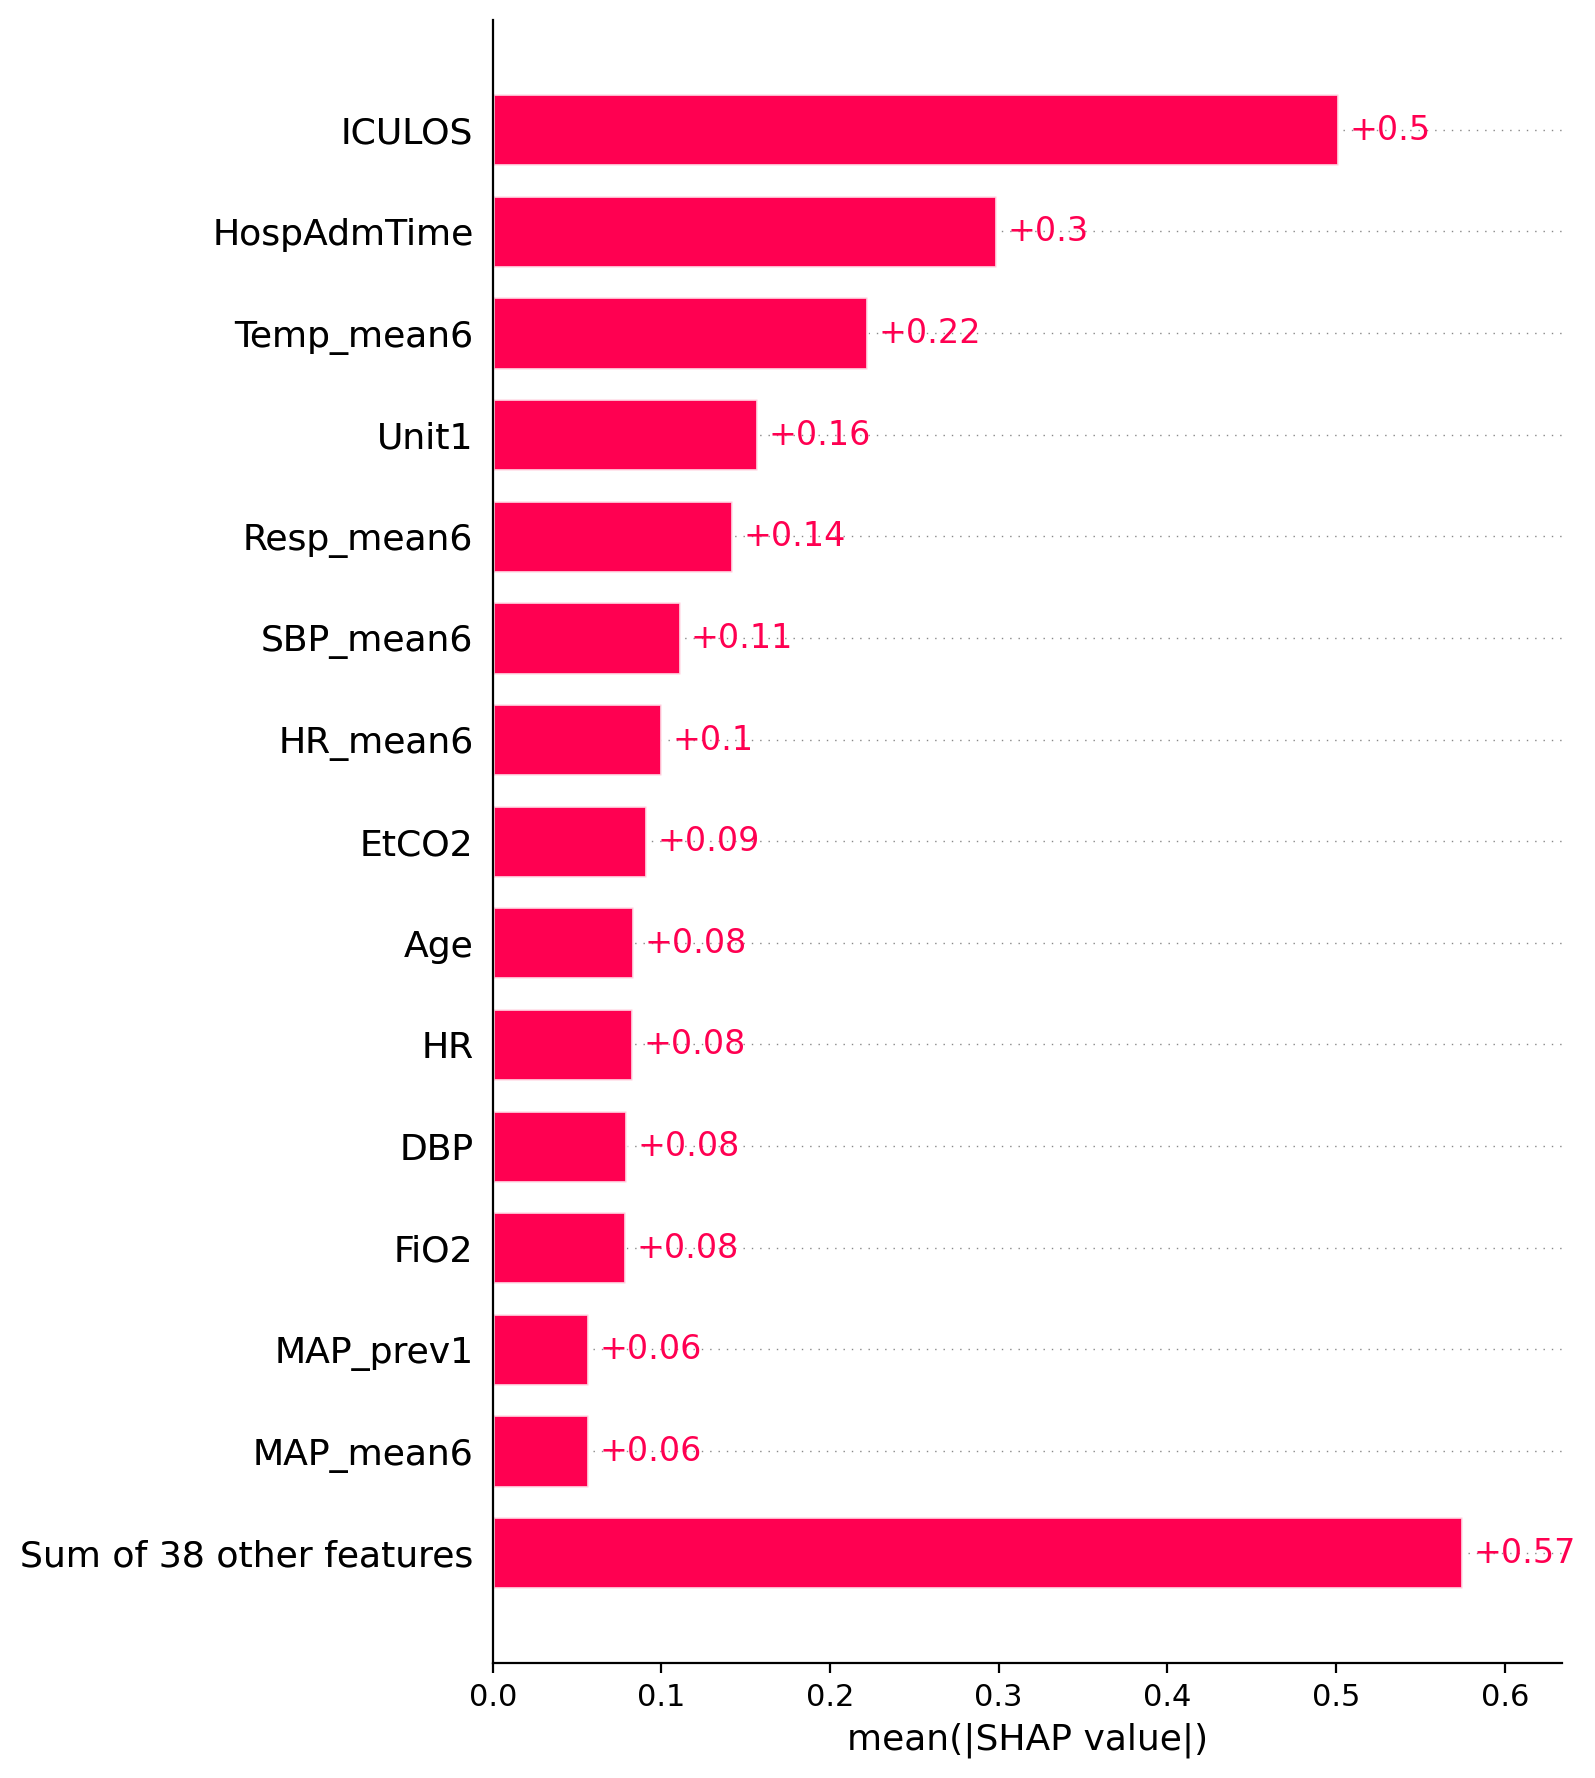

In [ ]:
# CELL 19 — Permanent SHAP visualization
# PURPOSE: Display existing global XGBoost explanations.
# This cell does not recalculate SHAP values.

from IPython.display import display, Image

shap_path = RESULTS_DIR / "shap_feature_importance.png"

if not shap_path.is_file():
    raise FileNotFoundError(f"SHAP chart not found: {shap_path}")

display(Image(filename=str(shap_path)))

In [ ]:
# CELL 20 — Permanent final-artifact verification
# PURPOSE: Verify key deliverables for the project demonstration.
# This cell only checks existing files.

final_files = [
    RESULTS_DIR / "final_model_comparison.csv",
    RESULTS_DIR / "shap_feature_importance.png",
    MODELS_DIR / "xgboost_sepsis.json",
    MODELS_DIR / "xgboost_tuned_candidate.json",
    MODELS_DIR / "lstm_sepsis.keras",
]

for path in final_files:
    print(("OK     " if path.is_file() else "MISSING"), path.name)

print("\nVerification complete.")

OK      final_model_comparison.csv
OK      shap_feature_importance.png
OK      xgboost_sepsis.json
OK      xgboost_tuned_candidate.json
OK      lstm_sepsis.keras

Verification complete.


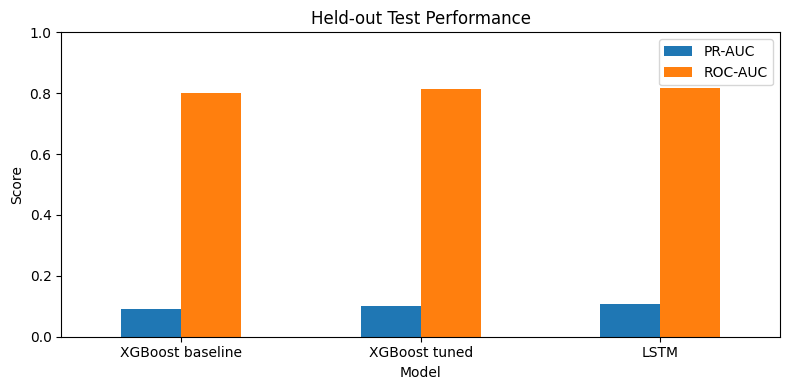

In [ ]:
# CELL 21 — Permanent model-comparison visualization
# PURPOSE: Compare saved held-out test metrics without retraining.

import matplotlib.pyplot as plt

metrics = comparison.set_index("Model")[["PR-AUC", "ROC-AUC"]]

ax = metrics.plot(kind="bar", figsize=(8, 4))
ax.set_title("Held-out Test Performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

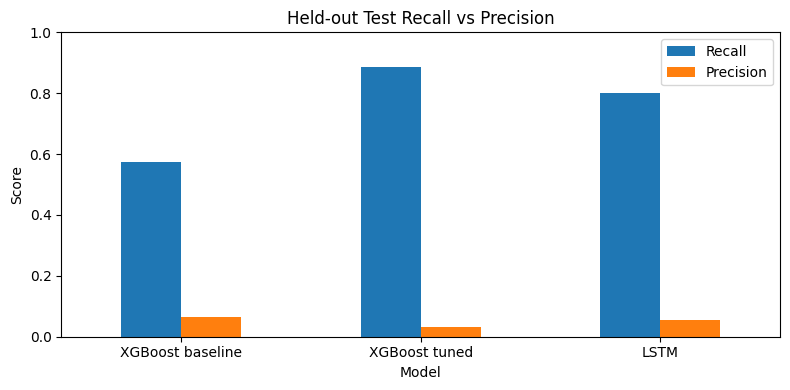

In [ ]:
# CELL 22 — Permanent recall/precision comparison
# PURPOSE: Visualize the saved test recall and precision.
# Uses existing metrics; no retraining or retuning.

metrics = comparison.set_index("Model")[["Recall", "Precision"]]

ax = metrics.plot(kind="bar", figsize=(8, 4))
ax.set_title("Held-out Test Recall vs Precision")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# CELL 23 — Permanent project summary
# PURPOSE: Print key dataset and model-evaluation facts.
# Uses verified results; does not retrain models.

print("EARLY SEPSIS PREDICTION — PROJECT SUMMARY")
print("-" * 45)
print(f"Patients: {len(all_patient_ids):,}")
print(f"Hourly records: {total_rows:,}")
print(f"Positive sepsis records: {total_positive:,}")
print(f"Positive-record rate: {100 * total_positive / total_rows:.3f}%")

print("\nBest PR-AUC:")
best_model = comparison.loc[comparison["PR-AUC"].idxmax()]
print(f"{best_model['Model']}: {best_model['PR-AUC']:.4f}")

print("\nClinical-use limitation:")
print("Research prototype only; not clinically validated.")

EARLY SEPSIS PREDICTION — PROJECT SUMMARY
---------------------------------------------
Patients: 40,336
Hourly records: 1,552,210
Positive sepsis records: 27,916
Positive-record rate: 1.798%

Best PR-AUC:
LSTM: 0.1067

Clinical-use limitation:
Research prototype only; not clinically validated.


In [ ]:
import json
import pandas as pd
from tqdm.auto import tqdm

PROCESSED = OUT / "processed"
CHECKPOINT = OUT / "checkpoints" / "completed_files.json"
BATCH_SIZE = 100

completed = set(json.loads(CHECKPOINT.read_text()))

# Include both source folders; distinguish patients by folder and filename
files = []
for folder in ["training_setA", "training_setB"]:
    files.extend(sorted((BASE / folder).glob("*.psv")))

files = [
    f for f in files
    if f"{f.parent.name}/{f.stem}" not in completed
]

print("Files remaining:", len(files))

for start in tqdm(range(0, len(files), BATCH_SIZE)):
    batch_files = files[start:start + BATCH_SIZE]
    frames = []

    for file in batch_files:
        df = pd.read_csv(file, sep="|")
        df["PatientID"] = f"{file.parent.name}_{file.stem}"
        frames.append(df)

    batch_df = pd.concat(frames, ignore_index=True)
    batch_number = start // BATCH_SIZE + 1
    output_file = PROCESSED / f"batch_{batch_number:04d}.parquet"

    batch_df.to_parquet(output_file, index=False)

    completed.update(f"{f.parent.name}/{f.stem}" for f in batch_files)
    CHECKPOINT.write_text(json.dumps(sorted(completed)))

print("Total completed:", len(completed))
print("All remaining batches saved.")

Files remaining: 40336


  0%|          | 0/404 [00:00<?, ?it/s]

Total completed: 40536
All remaining batches saved.


In [ ]:
import pandas as pd

PROCESSED = OUT / "processed"
batches = sorted(PROCESSED.glob("batch_*.parquet"))

patient_ids = set()
duplicates = set()
total_rows = 0

for file in batches:
    df = pd.read_parquet(file, columns=["PatientID"])
    ids = df["PatientID"].tolist()
    total_rows += len(ids)
    duplicates.update(pid for pid in ids if pid in patient_ids)
    patient_ids.update(ids)

print("Batch files:", len(batches))
print("Unique patients in batches:", len(patient_ids))
print("Duplicate patient IDs across batches:", len(duplicates))
print("Total hourly rows:", total_rows)

Batch files: 404
Unique patients in batches: 40336
Duplicate patient IDs across batches: 0
Total hourly rows: 1552210


In [ ]:
import pandas as pd

PROCESSED = OUT / "processed"
batches = sorted(PROCESSED.glob("batch_*.parquet"))

total_rows = 0
positive_hours = 0
patients = set()

for file in batches:
    df = pd.read_parquet(file)
    total_rows += len(df)
    positive_hours += int(df["SepsisLabel"].sum())
    patients.update(df["PatientID"].unique())

print("Hourly records:", total_rows)
print("Unique patients:", len(patients))
print("Positive sepsis hours:", positive_hours)
print("Positive rate (%):", round(100 * positive_hours / total_rows, 3))
print("Feature columns:", len(df.columns) - 2)  # excludes label and PatientID

Hourly records: 1552210
Unique patients: 40336
Positive sepsis hours: 27916
Positive rate (%): 1.798
Feature columns: 40


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

OUT = "/content/drive/MyDrive/Early_Sepsis_AI_Clean"
PROCESSED = f"{OUT}/processed"

batches = sorted(__import__("pathlib").Path(PROCESSED).glob("batch_*.parquet"))

# Read only patient IDs and labels to reduce memory use
parts = [
    pd.read_parquet(f, columns=["PatientID", "SepsisLabel"])
    for f in batches
]
data = pd.concat(parts, ignore_index=True)

patients = data[["PatientID"]].drop_duplicates()

train_ids, temp_ids = train_test_split(
    patients["PatientID"], test_size=0.30, random_state=42
)
val_ids, test_ids = train_test_split(
    temp_ids, test_size=0.50, random_state=42
)

split = {
    "train": set(train_ids),
    "validation": set(val_ids),
    "test": set(test_ids)
}

print("Train patients:", len(split["train"]))
print("Validation patients:", len(split["validation"]))
print("Test patients:", len(split["test"]))

Train patients: 28235
Validation patients: 6050
Test patients: 6051


In [ ]:
# Cell 11: Create temporal features for each patient.
# Purpose: Capture recent changes in vital signs without mixing patients.

from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
PROCESSED = OUT / "processed"
FEATURES = PROCESSED / "temporal_features"
FEATURES.mkdir(parents=True, exist_ok=True)

vitals = ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp"]

batches = sorted(PROCESSED.glob("batch_*.parquet"))

for file in tqdm(batches, desc="Creating temporal features"):
    df = pd.read_parquet(file)

    # Keep each patient's observations in their original hourly order.
    df = df.reset_index(drop=True)

    for col in vitals:
        if col in df.columns:
            df[f"{col}_prev1"] = df.groupby("PatientID")[col].shift(1)
            df[f"{col}_mean6"] = (
                df.groupby("PatientID")[col]
                .transform(lambda s: s.rolling(6, min_periods=1).mean())
            )

    output = FEATURES / file.name
    df.to_parquet(output, index=False)

print("Temporal feature files saved:", len(batches))
print("Location:", FEATURES)

Creating temporal features:   0%|          | 0/404 [00:00<?, ?it/s]

Temporal feature files saved: 404
Location: /content/drive/MyDrive/Early_Sepsis_AI_Clean/processed/temporal_features


In [ ]:
# Cell 13: Define model features and target.
# Purpose: Keep the same valid input features for fair model comparison.

from pathlib import Path
import pandas as pd

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"

sample_file = sorted(FEATURES.glob("batch_*.parquet"))[0]
sample = pd.read_parquet(sample_file)

TARGET = "SepsisLabel"
EXCLUDE = {"PatientID", TARGET}

FEATURE_COLS = [
    col for col in sample.columns
    if col not in EXCLUDE
]

print("Input features:", len(FEATURE_COLS))
print("Target:", TARGET)
print("PatientID excluded:", "PatientID" not in FEATURE_COLS)
print("SepsisLabel excluded:", TARGET not in FEATURE_COLS)

Input features: 52
Target: SepsisLabel
PatientID excluded: True
SepsisLabel excluded: True


In [ ]:
# Cell 14: Set up model training.
# Purpose: Confirm required libraries and define reproducible settings.

import xgboost as xgb
import sklearn
import numpy as np
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("XGBoost version:", xgb.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Random seed:", SEED)
print("Input features:", len(FEATURE_COLS))

XGBoost version: 3.4.1
Scikit-learn version: 1.6.1
Random seed: 42
Input features: 52


In [ ]:
# Cell 15: Load saved patient-level train/validation/test split.
# Purpose: Reuse the same split after runtime restarts.

import json
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

train_ids = set(split["train"])
val_ids = set(split["validation"])
test_ids = set(split["test"])

print("Train patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Test patients:", len(test_ids))
print("Patient overlap:", bool(
    (train_ids & val_ids) or
    (train_ids & test_ids) or
    (val_ids & test_ids)
))

Train patients: 28235
Validation patients: 6050
Test patients: 6051
Patient overlap: False


In [ ]:
# Cell 16: Prepare XGBoost training data.
# Purpose: Save training features and labels separately for efficient model training.

import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"
TRAIN_DIR = OUT / "processed" / "train_data"
TRAIN_DIR.mkdir(parents=True, exist_ok=True)

X_parts, y_parts = [], []

for file in tqdm(sorted(FEATURES.glob("batch_*.parquet"))):
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(train_ids)]

    if not df.empty:
        X_parts.append(df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan))
        y_parts.append(df["SepsisLabel"].astype("int8"))

X_train = pd.concat(X_parts, ignore_index=True)
y_train = pd.concat(y_parts, ignore_index=True)

X_train.to_parquet(TRAIN_DIR / "X_train.parquet", index=False)
y_train.to_frame("SepsisLabel").to_parquet(TRAIN_DIR / "y_train.parquet", index=False)

print("Training rows:", len(X_train))
print("Positive hours:", int(y_train.sum()))
print("Features:", X_train.shape[1])
print("Saved to:", TRAIN_DIR)

  0%|          | 0/404 [00:00<?, ?it/s]

Training rows: 1087702
Positive hours: 19845
Features: 52
Saved to: /content/drive/MyDrive/Early_Sepsis_AI_Clean/processed/train_data


In [ ]:
# Cell 17: Prepare XGBoost validation data.
# Purpose: Evaluate model settings and tune the recall threshold.

import pandas as pd
import numpy as np
from tqdm.auto import tqdm

VAL_DIR = OUT / "processed" / "validation_data"
VAL_DIR.mkdir(parents=True, exist_ok=True)

X_parts, y_parts = [], []

for file in tqdm(sorted(FEATURES.glob("batch_*.parquet"))):
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(val_ids)]

    if not df.empty:
        X_parts.append(df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan))
        y_parts.append(df["SepsisLabel"].astype("int8"))

X_val = pd.concat(X_parts, ignore_index=True)
y_val = pd.concat(y_parts, ignore_index=True)

X_val.to_parquet(VAL_DIR / "X_val.parquet", index=False)
y_val.to_frame("SepsisLabel").to_parquet(VAL_DIR / "y_val.parquet", index=False)

print("Validation rows:", len(X_val))
print("Positive hours:", int(y_val.sum()))
print("Saved to:", VAL_DIR)

  0%|          | 0/404 [00:00<?, ?it/s]

Validation rows: 232885
Positive hours: 4037
Saved to: /content/drive/MyDrive/Early_Sepsis_AI_Clean/processed/validation_data


In [ ]:
# Cell 18: Train the temporal XGBoost model.
# Purpose: Learn sepsis risk patterns while accounting for class imbalance.

import xgboost as xgb
import pandas as pd
import numpy as np
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
TRAIN_DIR = OUT / "processed" / "train_data"
MODEL_DIR = OUT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_parquet(TRAIN_DIR / "X_train.parquet")
y_train = pd.read_parquet(TRAIN_DIR / "y_train.parquet")["SepsisLabel"]

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

model.fit(X_train, y_train)
model.save_model(str(MODEL_DIR / "xgboost_sepsis.json"))

print("XGBoost training complete.")
print("Positive-class weight:", round(scale_pos_weight, 2))
print("Model saved to:", MODEL_DIR / "xgboost_sepsis.json")

XGBoost training complete.
Positive-class weight: 53.81
Model saved to: /content/drive/MyDrive/Early_Sepsis_AI_Clean/models/xgboost_sepsis.json


In [ ]:
# Cell 19: Evaluate XGBoost on validation data.
# Purpose: Measure ranking performance before choosing a recall-focused threshold.

import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

OUT = "/content/drive/MyDrive/Early_Sepsis_AI_Clean"
VAL_DIR = f"{OUT}/processed/validation_data"

X_val = pd.read_parquet(f"{VAL_DIR}/X_val.parquet")
y_val = pd.read_parquet(f"{VAL_DIR}/y_val.parquet")["SepsisLabel"]

probs = model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:", round(roc_auc_score(y_val, probs), 4))
print("Validation PR-AUC:", round(average_precision_score(y_val, probs), 4))
print("Validation rows:", len(y_val))

Validation ROC-AUC: 0.8263
Validation PR-AUC: 0.105
Validation rows: 232885


In [ ]:
# Cell 20: Select a recall-focused decision threshold.
# Purpose: Choose a threshold on validation data and report its trade-offs.

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    pred = (probs >= threshold).astype(int)
    print(
        f"Threshold={threshold:.2f} | "
        f"Recall={recall_score(y_val, pred):.3f} | "
        f"Precision={precision_score(y_val, pred, zero_division=0):.3f} | "
        f"F1={f1_score(y_val, pred, zero_division=0):.3f}"
    )

Threshold=0.05 | Recall=0.995 | Precision=0.018 | F1=0.036
Threshold=0.10 | Recall=0.974 | Precision=0.021 | F1=0.042
Threshold=0.15 | Recall=0.946 | Precision=0.026 | F1=0.050
Threshold=0.20 | Recall=0.907 | Precision=0.031 | F1=0.059
Threshold=0.30 | Recall=0.828 | Precision=0.042 | F1=0.080
Threshold=0.50 | Recall=0.626 | Precision=0.070 | F1=0.125


In [ ]:
# Cell 22: Train a tuned XGBoost candidate.
# Purpose: Test a shallower, regularized model to reduce false alarms.

import xgboost as xgb
import pandas as pd
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
TRAIN_DIR = OUT / "processed" / "train_data"
MODEL_DIR = OUT / "models"

X_train = pd.read_parquet(TRAIN_DIR / "X_train.parquet")
y_train = pd.read_parquet(TRAIN_DIR / "y_train.parquet")["SepsisLabel"]

candidate = xgb.XGBClassifier(
    n_estimators=700,
    max_depth=4,
    learning_rate=0.04,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=20,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

candidate.fit(X_train, y_train)
candidate.save_model(str(MODEL_DIR / "xgboost_tuned_candidate.json"))

print("Tuned candidate trained and saved.")

Tuned candidate trained and saved.


In [ ]:
# Cell 23: Compare original and tuned XGBoost.
# Purpose: Compare PR-AUC and recall/precision at threshold 0.20.

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, recall_score, precision_score, f1_score

X_val = pd.read_parquet(OUT / "processed" / "validation_data" / "X_val.parquet")
y_val = pd.read_parquet(OUT / "processed" / "validation_data" / "y_val.parquet")["SepsisLabel"]

original = xgb.XGBClassifier()
original.load_model(str(OUT / "models" / "xgboost_sepsis.json"))

for name, model_to_test in [("Original", original), ("Tuned", candidate)]:
    p = model_to_test.predict_proba(X_val)[:, 1]
    pred = (p >= 0.20).astype(int)

    print(
        name,
        "| PR-AUC:", round(average_precision_score(y_val, p), 4),
        "| Recall:", round(recall_score(y_val, pred), 4),
        "| Precision:", round(precision_score(y_val, pred, zero_division=0), 4),
        "| F1:", round(f1_score(y_val, pred, zero_division=0), 4)
    )

Original | PR-AUC: 0.105 | Recall: 0.9066 | Precision: 0.0306 | F1: 0.0592
Tuned | PR-AUC: 0.1287 | Recall: 0.8088 | Precision: 0.0465 | F1: 0.088


In [ ]:
# Cell 24: Find a validation threshold for at least 90% recall.
# Purpose: Improve recall while measuring the resulting false alarms.

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import recall_score, precision_score, f1_score

OUT = "/content/drive/MyDrive/Early_Sepsis_AI_Clean"

X_val = pd.read_parquet(f"{OUT}/processed/validation_data/X_val.parquet")
y_val = pd.read_parquet(f"{OUT}/processed/validation_data/y_val.parquet")["SepsisLabel"]

model = xgb.XGBClassifier()
model.load_model(f"{OUT}/models/xgboost_tuned_candidate.json")
probs = model.predict_proba(X_val)[:, 1]

results = []
for t in np.arange(0.01, 0.501, 0.01):
    pred = (probs >= t).astype(int)
    results.append({
        "threshold": round(float(t), 2),
        "recall": recall_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0)
    })

table = pd.DataFrame(results)
eligible = table[table["recall"] >= 0.90]

if not eligible.empty:
    best = eligible.sort_values("precision", ascending=False).iloc[0]
    print("Selected validation threshold:", best["threshold"])
    print("Recall:", round(best["recall"], 4))
    print("Precision:", round(best["precision"], 4))
    print("F1:", round(best["f1"], 4))
else:
    print("No threshold in this range achieved 90% recall.")

Selected validation threshold: 0.13
Recall: 0.9091
Precision: 0.0329
F1: 0.0636


In [ ]:
# Cell 27: Check LSTM sequence preparation requirements.
# Purpose: Confirm feature columns, labels, and patient identifiers.

import pandas as pd
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"

sample = pd.read_parquet(sorted(FEATURES.glob("batch_*.parquet"))[0])

FEATURE_COLS = [
    c for c in sample.columns
    if c not in {"PatientID", "SepsisLabel"}
]

print("Feature count:", len(FEATURE_COLS))
print("PatientID available:", "PatientID" in sample.columns)
print("SepsisLabel available:", "SepsisLabel" in sample.columns)
print("Sequence length: 24 hours")
print("Missing feature values:", int(sample[FEATURE_COLS].isna().sum().sum()))

Feature count: 52
PatientID available: True
SepsisLabel available: True
Sequence length: 24 hours
Missing feature values: 109867


In [ ]:
# Cell 28: Measure missing values in the temporal features.
# Purpose: Identify columns that need imputation before LSTM training.

# Check missingness in one batch without loading the full dataset.
missing_pct = (
    sample[FEATURE_COLS].isna().mean().mul(100)
    .sort_values(ascending=False)
)

print("Columns with most missing values (%):")
print(missing_pct.head(15).round(2))

Columns with most missing values (%):
EtCO2               100.00
Bilirubin_direct     99.89
TroponinI            99.89
Fibrinogen           99.33
Bilirubin_total      98.68
Alkalinephos         98.41
AST                  98.30
Lactate              96.36
SaO2                 96.03
PTT                  95.46
Calcium              95.01
Phosphate            94.84
Platelets            93.36
Creatinine           92.90
Magnesium            92.49
dtype: float64


In [ ]:
# Cell 29: Select LSTM features using missingness from the training patients.
# Purpose: Keep features with at least 20% observed values in the training data.

import json
import pandas as pd
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

train_ids = set(split["train"])
files = sorted(FEATURES.glob("batch_*.parquet"))

observed = pd.Series(0, index=FEATURE_COLS, dtype="int64")
total = pd.Series(0, index=FEATURE_COLS, dtype="int64")

for file in files:
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(train_ids)]
    if df.empty:
        continue
    observed += df[FEATURE_COLS].notna().sum()
    total += len(df)

missing_pct_train = (1 - observed / total) * 100
LSTM_FEATURES = missing_pct_train[missing_pct_train <= 80].index.tolist()

print("Original features:", len(FEATURE_COLS))
print("LSTM features retained:", len(LSTM_FEATURES))
print("Retained features:", LSTM_FEATURES)
print("Removed features:", sorted(set(FEATURE_COLS) - set(LSTM_FEATURES)))

Original features: 52
LSTM features retained: 25
Retained features: ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'HR_prev1', 'HR_mean6', 'O2Sat_prev1', 'O2Sat_mean6', 'Temp_prev1', 'Temp_mean6', 'SBP_prev1', 'SBP_mean6', 'MAP_prev1', 'MAP_mean6', 'Resp_prev1', 'Resp_mean6']
Removed features: ['AST', 'Alkalinephos', 'BUN', 'BaseExcess', 'Bilirubin_direct', 'Bilirubin_total', 'Calcium', 'Chloride', 'Creatinine', 'EtCO2', 'FiO2', 'Fibrinogen', 'Glucose', 'HCO3', 'Hct', 'Hgb', 'Lactate', 'Magnesium', 'PTT', 'PaCO2', 'Phosphate', 'Platelets', 'Potassium', 'SaO2', 'TroponinI', 'WBC', 'pH']


In [ ]:
# Cell 30: Fit LSTM preprocessing on training patients only.
# Purpose: Impute missing values and scale features without validation/test leakage.

import numpy as np
import joblib
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_train_path = OUT / "processed" / "train_data" / "X_train.parquet"

X_train = pd.read_parquet(X_train_path)
X_train = X_train[LSTM_FEATURES]

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train)
X_train_scaled = scaler.fit_transform(X_train_imputed).astype(np.float32)

prep_dir = OUT / "models"
prep_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(imputer, prep_dir / "lstm_imputer.joblib")
joblib.dump(scaler, prep_dir / "lstm_scaler.joblib")
joblib.dump(LSTM_FEATURES, prep_dir / "lstm_features.joblib")

print("Training rows:", X_train_scaled.shape[0])
print("Features:", X_train_scaled.shape[1])
print("Any NaN after preprocessing:", bool(np.isnan(X_train_scaled).any()))

Training rows: 1087702
Features: 25
Any NaN after preprocessing: False


In [ ]:
# Cell 35: Prepare paths and load the patient split for LSTM training.
# Purpose: Set up patient-level data access without loading all batches into memory.

from pathlib import Path
import json
import pandas as pd
import joblib

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"
MODEL_DIR = OUT / "models"

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

LSTM_FEATURES = joblib.load(MODEL_DIR / "lstm_features.joblib")
imputer = joblib.load(MODEL_DIR / "lstm_imputer.joblib")
scaler = joblib.load(MODEL_DIR / "lstm_scaler.joblib")

batch_files = sorted(FEATURES.glob("batch_*.parquet"))

print("Batch files:", len(batch_files))
print("Training patients:", len(split["train"]))
print("Validation patients:", len(split["validation"]))
print("LSTM features:", len(LSTM_FEATURES))
print("Setup ready.")

Batch files: 404
Training patients: 28235
Validation patients: 6050
LSTM features: 25
Setup ready.


In [ ]:
# Cell 36: Define a batch-based LSTM data pipeline.
# Purpose: Stream 24-hour patient sequences in small batches.

import numpy as np
import tensorflow as tf
from collections import deque

SEQUENCE_LENGTH = 24
BATCH_SIZE = 128

def sequence_generator(patient_ids, batch_files, feature_cols,
                       imputer, scaler, sequence_length=24,
                       batch_size=128):
    batch_X, batch_y = [], []
    patient_ids = set(patient_ids)

    for file in batch_files:
        df = pd.read_parquet(file)
        df = df[df["PatientID"].isin(patient_ids)]

        for _, patient in df.groupby("PatientID", sort=False):
            patient = patient.sort_values("ICULOS")
            X = patient[feature_cols]
            X = scaler.transform(imputer.transform(X)).astype(np.float32)
            y = patient["SepsisLabel"].to_numpy(dtype=np.float32)

            for end in range(sequence_length - 1, len(patient)):
                batch_X.append(X[end-sequence_length+1:end+1])
                batch_y.append(y[end])

                if len(batch_X) >= batch_size:
                    yield np.asarray(batch_X), np.asarray(batch_y)
                    batch_X, batch_y = [], []

    if batch_X:
        yield np.asarray(batch_X), np.asarray(batch_y)

print("Batch generator defined.")
print("Sequence shape:", (SEQUENCE_LENGTH, len(LSTM_FEATURES)))
print("Batch size:", BATCH_SIZE)

Batch generator defined.
Sequence shape: (24, 25)
Batch size: 128


In [ ]:
# Cell 37: Define a compact LSTM model.
# Purpose: Predict the sepsis label for the final hour of each 24-hour sequence.

import tensorflow as tf

tf.keras.utils.set_random_seed(42)

lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, len(LSTM_FEATURES))),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         7,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,969 (31.13 KB)

 Trainable params: 7,969 (31.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Cell 38: Check class balance before LSTM training.
# Purpose: Calculate class weights from training labels only.

from pathlib import Path
import pandas as pd
import numpy as np

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
TRAIN_Y = OUT / "processed" / "train_data" / "y_train.parquet"

y_train = pd.read_parquet(TRAIN_Y).iloc[:, 0].to_numpy()
counts = np.bincount(y_train.astype(int))

print("Negative labels:", counts[0])
print("Positive labels:", counts[1])
print("Positive rate (%):", round(100 * counts[1] / len(y_train), 3))
print("Training labels verified.")

Negative labels: 1067857
Positive labels: 19845
Positive rate (%): 1.824
Training labels verified.


In [ ]:
# Cell 39: Run a short LSTM training test.
# Purpose: Verify the patient-wise sequence pipeline before longer training.

import tensorflow as tf
import numpy as np
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
MODEL_DIR = OUT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_gen = sequence_generator(
    split["train"], batch_files, LSTM_FEATURES,
    imputer, scaler, sequence_length=24, batch_size=128
)

val_gen = sequence_generator(
    split["validation"], batch_files, LSTM_FEATURES,
    imputer, scaler, sequence_length=24, batch_size=128
)

def dataset_from_generator(patient_ids):
    return tf.data.Dataset.from_generator(
        lambda: sequence_generator(
            patient_ids, batch_files, LSTM_FEATURES,
            imputer, scaler, sequence_length=24, batch_size=128
        ),
        output_signature=(
            tf.TensorSpec((None, 24, len(LSTM_FEATURES)), tf.float32),
            tf.TensorSpec((None,), tf.float32)
        )
    ).prefetch(1)

train_ds = dataset_from_generator(split["train"])
val_ds = dataset_from_generator(split["validation"])

class_weights = {
    0: 1.0,
    1: float(counts[0] / counts[1])
}

history = lstm_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    class_weight=class_weights
)

lstm_model.save(MODEL_DIR / "lstm_sepsis.keras")
print("Saved LSTM model.")

Epoch 1/2
   3704/Unknown 153s 40ms/step - loss: 1.4061 - pr_auc: 0.0977 - recall: 0.8203 - roc_auc: 0.7671

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3704/3704 ━━━━━━━━━━━━━━━━━━━━ 182s 48ms/step - loss: 1.2694 - pr_auc: 0.0981 - recall: 0.7866 - roc_auc: 0.7900 - val_loss: 0.6194 - val_pr_auc: 0.1127 - val_recall: 0.7912 - val_roc_auc: 0.8245
Epoch 2/2


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3703/3704 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 1.3215 - pr_auc: 0.1155 - recall: 0.7890 - roc_auc: 0.7991

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


3704/3704 ━━━━━━━━━━━━━━━━━━━━ 173s 47ms/step - loss: 1.2201 - pr_auc: 0.1123 - recall: 0.7782 - roc_auc: 0.8081 - val_loss: 0.6098 - val_pr_auc: 0.1210 - val_recall: 0.8149 - val_roc_auc: 0.8307


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Saved LSTM model.


In [ ]:
# Cell 41: Prepare held-out test data.
# Purpose: Save test features and labels for final evaluation of both models.

from pathlib import Path
import json
import pandas as pd

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"
TEST_DIR = OUT / "processed" / "test_data"
TEST_DIR.mkdir(parents=True, exist_ok=True)

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

test_ids = set(split["test"])
files = sorted(FEATURES.glob("batch_*.parquet"))

X_parts, y_parts = [], []

for file in files:
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(test_ids)]
    if df.empty:
        continue

    X_parts.append(df.drop(columns=["PatientID", "SepsisLabel"]))
    y_parts.append(df[["SepsisLabel"]])

X_test = pd.concat(X_parts, ignore_index=True)
y_test = pd.concat(y_parts, ignore_index=True)

X_test.to_parquet(TEST_DIR / "X_test.parquet", index=False)
y_test.to_parquet(TEST_DIR / "y_test.parquet", index=False)

print("Test rows:", len(X_test))
print("Test patients:", len(test_ids))
print("Positive labels:", int(y_test["SepsisLabel"].sum()))
print("Saved test data successfully.")

Test rows: 231623
Test patients: 6051
Positive labels: 4034
Saved test data successfully.


In [ ]:
# Cell 42: Evaluate XGBoost models on held-out test patients.
# Purpose: Compare baseline and tuned models using identical test data.

from pathlib import Path
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score
)

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
MODEL_DIR = OUT / "models"
TEST_DIR = OUT / "processed" / "test_data"
RESULTS = OUT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

X_test = pd.read_parquet(TEST_DIR / "X_test.parquet")
y_test = pd.read_parquet(TEST_DIR / "y_test.parquet")["SepsisLabel"].to_numpy()

# Align test columns to the training feature order.
sample = pd.read_parquet(
    sorted((OUT / "processed" / "temporal_features").glob("batch_*.parquet"))[0]
)
FEATURE_COLS = [c for c in sample.columns if c not in {"PatientID", "SepsisLabel"}]
X_test = X_test[FEATURE_COLS]

models = {
    "XGBoost baseline": "xgboost_sepsis.json",
    "XGBoost tuned": "xgboost_tuned_candidate.json"
}

rows = []

for name, filename in models.items():
    model = xgb.XGBClassifier()
    model.load_model(MODEL_DIR / filename)
    probabilities = model.predict_proba(X_test)[:, 1]

    # Use thresholds selected on validation data, not test data.
    threshold = 0.50 if name == "XGBoost baseline" else 0.13
    predictions = (probabilities >= threshold).astype(int)

    rows.append({
        "Model": name,
        "Threshold": threshold,
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    })

metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS / "xgboost_test_metrics.csv", index=False)
print(metrics.round(4).to_string(index=False))
print("\nSaved:", RESULTS / "xgboost_test_metrics.csv")

           Model  Threshold  PR-AUC  ROC-AUC  Recall  Precision     F1
XGBoost baseline       0.50  0.0909   0.8016  0.5756     0.0640 0.1152
   XGBoost tuned       0.13  0.1003   0.8138  0.8845     0.0316 0.0610

Saved: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/xgboost_test_metrics.csv


In [ ]:
# Cell 43: Verify saved LSTM model and preprocessing artifacts.
# Purpose: Confirm everything needed for LSTM test evaluation is available.

from pathlib import Path
import tensorflow as tf
import joblib

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
MODEL_DIR = OUT / "models"

lstm_model = tf.keras.models.load_model(MODEL_DIR / "lstm_sepsis.keras")
imputer = joblib.load(MODEL_DIR / "lstm_imputer.joblib")
scaler = joblib.load(MODEL_DIR / "lstm_scaler.joblib")
LSTM_FEATURES = joblib.load(MODEL_DIR / "lstm_features.joblib")

print("LSTM loaded:", lstm_model is not None)
print("LSTM input shape:", lstm_model.input_shape)
print("Selected features:", len(LSTM_FEATURES))
print("Preprocessing artifacts loaded.")

LSTM loaded: True
LSTM input shape: (None, 24, 25)
Selected features: 25
Preprocessing artifacts loaded.


In [ ]:
# Cell 44: Evaluate the saved LSTM on held-out test patients.
# Purpose: Calculate test PR-AUC, ROC-AUC, recall, precision, and F1.

from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    recall_score, precision_score, f1_score
)

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
FEATURES = OUT / "processed" / "temporal_features"
RESULTS = OUT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

with open(OUT / "checkpoints" / "patient_split.json") as f:
    split = json.load(f)

test_ids = set(split["test"])
y_true_parts, y_prob_parts = [], []

for file in sorted(FEATURES.glob("batch_*.parquet")):
    df = pd.read_parquet(file)
    df = df[df["PatientID"].isin(test_ids)]

    for _, patient in df.groupby("PatientID", sort=False):
        patient = patient.sort_values("ICULOS")
        if len(patient) < 24:
            continue

        X = patient[LSTM_FEATURES]
        X = scaler.transform(imputer.transform(X)).astype(np.float32)
        y = patient["SepsisLabel"].to_numpy(dtype=np.int8)

        # Predict in small overlapping windows, keeping each patient separate.
        windows = np.lib.stride_tricks.sliding_window_view(
            X, window_shape=24, axis=0
        ).transpose(0, 2, 1)

        probabilities = lstm_model.predict(
            windows, batch_size=128, verbose=0
        ).ravel()

        y_true_parts.append(y[23:])
        y_prob_parts.append(probabilities)

y_true = np.concatenate(y_true_parts)
y_prob = np.concatenate(y_prob_parts)

threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)

lstm_metrics = {
    "Model": "LSTM",
    "Threshold": threshold,
    "PR-AUC": average_precision_score(y_true, y_prob),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "F1": f1_score(y_true, y_pred, zero_division=0)
}

print(pd.DataFrame([lstm_metrics]).round(4).to_string(index=False))

pd.DataFrame([lstm_metrics]).to_csv(
    RESULTS / "lstm_test_metrics.csv", index=False
)
print("\nSaved LSTM test metrics.")

Model  Threshold  PR-AUC  ROC-AUC  Recall  Precision    F1
 LSTM        0.5  0.1067   0.8166  0.7991     0.0562 0.105

Saved LSTM test metrics.


In [ ]:
# Cell 45: Save the final test comparison.
# Purpose: Combine saved metrics for reporting and website use.

from pathlib import Path
import pandas as pd

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
RESULTS = OUT / "results"

xgb_results = pd.read_csv(RESULTS / "xgboost_test_metrics.csv")
lstm_results = pd.read_csv(RESULTS / "lstm_test_metrics.csv")

comparison = pd.concat([xgb_results, lstm_results], ignore_index=True)
comparison.to_csv(RESULTS / "final_model_comparison.csv", index=False)

print(comparison.round(4).to_string(index=False))
print("\nSaved:", RESULTS / "final_model_comparison.csv")

           Model  Threshold  PR-AUC  ROC-AUC  Recall  Precision     F1
XGBoost baseline       0.50  0.0909   0.8016  0.5756     0.0640 0.1152
   XGBoost tuned       0.13  0.1003   0.8138  0.8845     0.0316 0.0610
            LSTM       0.50  0.1067   0.8166  0.7991     0.0562 0.1050

Saved: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/final_model_comparison.csv


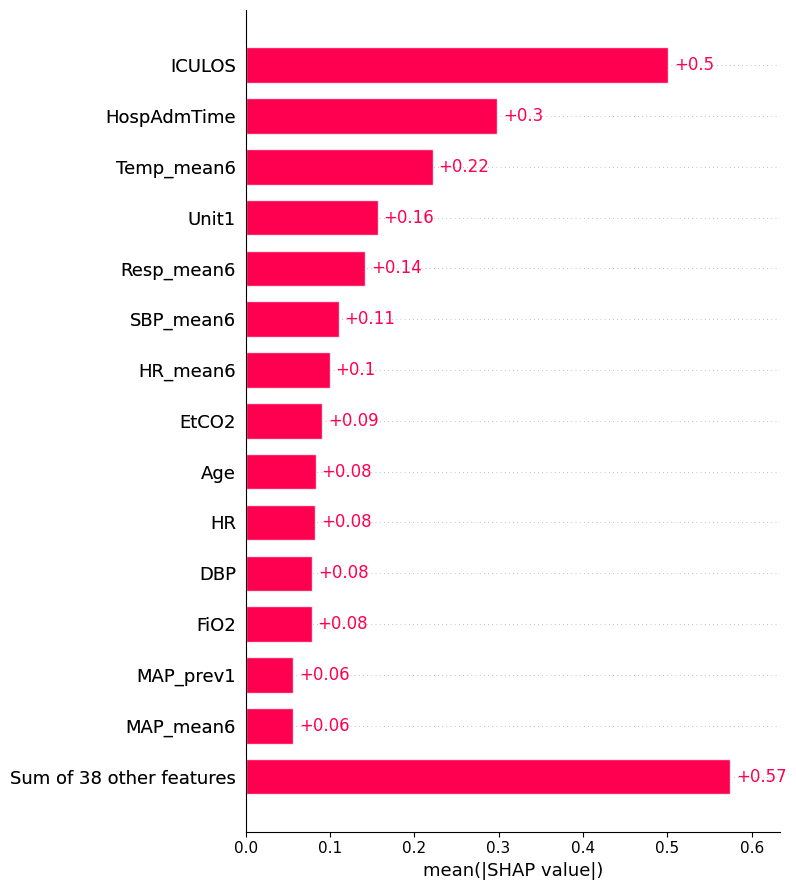

Saved SHAP chart: /content/drive/MyDrive/Early_Sepsis_AI_Clean/results/shap_feature_importance.png


In [ ]:
# Cell 47: Explain XGBoost predictions with SHAP.
# Purpose: Identify the clinical features that most influence model predictions.

import shap
import xgboost as xgb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
MODEL_DIR = OUT / "models"
RESULTS = OUT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

X_test = pd.read_parquet(OUT / "processed" / "test_data" / "X_test.parquet")

sample = pd.read_parquet(
    sorted((OUT / "processed" / "temporal_features").glob("batch_*.parquet"))[0]
)
FEATURE_COLS = [
    c for c in sample.columns
    if c not in {"PatientID", "SepsisLabel"}
]
X_test = X_test[FEATURE_COLS].sample(
    n=min(500, len(X_test)), random_state=42
)

model = xgb.XGBClassifier()
model.load_model(MODEL_DIR / "xgboost_tuned_candidate.json")

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig(RESULTS / "shap_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved SHAP chart:", RESULTS / "shap_feature_importance.png")

In [ ]:
# Cell 48: Create the Streamlit dashboard files.
# Purpose: Build a dashboard for model comparison, SHAP explanations, and risk prediction.

from pathlib import Path

OUT = Path("/content/drive/MyDrive/Early_Sepsis_AI_Clean")
WEB = OUT / "website"
WEB.mkdir(parents=True, exist_ok=True)

app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
import joblib
import json
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import average_precision_score

st.set_page_config(page_title="Sepsis AI", page_icon="🩺", layout="wide")

BASE = Path(__file__).resolve().parent.parent
MODELS = BASE / "models"
RESULTS = BASE / "results"
DATA = BASE / "processed"

st.title("🩺 Early Sepsis Detection")
st.caption("Explainable AI research prototype | PhysioNet 2019")

st.warning(
    "Research prototype only. Not validated for clinical use. "
    "Do not use this dashboard to make patient-care decisions."
)

@st.cache_resource
def load_xgb():
    model = xgb.XGBClassifier()
    model.load_model(str(MODELS / "xgboost_tuned_candidate.json"))
    return model

@st.cache_resource
def load_lstm():
    import tensorflow as tf
    return tf.keras.models.load_model(MODELS / "lstm_sepsis.keras")

@st.cache_data
def load_comparison():
    return pd.read_csv(RESULTS / "final_model_comparison.csv")

tab1, tab2, tab3, tab4 = st.tabs([
    "Overview", "Model Comparison", "Risk Prediction", "Explainability"
])

with tab1:
    st.subheader("Project Overview")
    c1, c2, c3 = st.columns(3)
    c1.metric("Patients processed", "40,336")
    c2.metric("Hourly records", "1.55 million")
    c3.metric("Input features", "52")
    st.write(
        "This project compares XGBoost and LSTM models for predicting "
        "sepsis-labelled hours from ICU observations."
    )
    st.info(
        "The models predict dataset labels, not confirmed clinical diagnoses. "
        "Performance depends on the threshold and evaluation method."
    )

with tab2:
    st.subheader("Held-out Test Results")
    comparison = load_comparison()
    st.dataframe(comparison.round(4), use_container_width=True)
    st.bar_chart(comparison.set_index("Model")[["PR-AUC", "ROC-AUC", "F1"]])
    st.caption(
        "Recall and precision use the listed thresholds. "
        "The tuned XGBoost threshold was selected using validation data."
    )

with tab3:
    st.subheader("Predict from uploaded observations")
    st.write(
        "Upload a CSV containing the model's required feature columns. "
        "For LSTM, provide at least 24 chronological hourly rows for one patient."
    )
    model_choice = st.selectbox("Model", ["Tuned XGBoost", "LSTM"])
    uploaded = st.file_uploader("Upload feature CSV", type=["csv"])

    if uploaded:
        df = pd.read_csv(uploaded)
        features = joblib.load(MODELS / "lstm_features.joblib")
        sample = pd.read_parquet(
            sorted((DATA / "temporal_features").glob("batch_*.parquet"))[0]
        )
        xgb_features = [
            c for c in sample.columns if c not in ["PatientID", "SepsisLabel"]
        ]

        if model_choice == "Tuned XGBoost":
            missing = sorted(set(xgb_features) - set(df.columns))
            if missing:
                st.error(f"Missing required columns: {', '.join(missing)}")
            else:
                model = load_xgb()
                probability = model.predict_proba(df[xgb_features])[:, 1]
                st.dataframe(pd.DataFrame({
                    "Row": np.arange(1, len(probability) + 1),
                    "Predicted probability": probability,
                    "Flag at threshold 0.13": probability >= 0.13
                }))
                st.caption("Threshold 0.13 is a research threshold, not a clinical alarm threshold.")

        else:
            if len(df) < 24:
                st.error("LSTM requires at least 24 chronological hourly rows.")
            elif not set(features).issubset(df.columns):
                st.error("CSV is missing one or more required LSTM features.")
            else:
                imputer = joblib.load(MODELS / "lstm_imputer.joblib")
                scaler = joblib.load(MODELS / "lstm_scaler.joblib")
                X = scaler.transform(imputer.transform(df[features])).astype(np.float32)
                windows = np.lib.stride_tricks.sliding_window_view(
                    X, window_shape=24, axis=0
                ).transpose(0, 2, 1)
                probabilities = load_lstm().predict(windows, verbose=0).ravel()
                st.dataframe(pd.DataFrame({
                    "Ending hour": np.arange(24, len(df) + 1),
                    "Predicted probability": probabilities,
                    "Flag at threshold 0.50": probabilities >= 0.50
                }))

with tab4:
    st.subheader("Global Feature Importance (SHAP)")
    chart = RESULTS / "shap_feature_importance.png"
    if chart.exists():
        st.image(str(chart), caption="Mean absolute SHAP values on a test-record sample")
    else:
        st.info("SHAP chart not found. Generate it from the notebook first.")
    st.caption(
        "SHAP describes model influence, not causation. "
        "Time-related features such as ICULOS may strongly influence predictions."
    )
'''

(WEB / "app.py").write_text(app_code, encoding="utf-8")

(WEB / "requirements.txt").write_text(
    "streamlit\npandas\nnumpy\nxgboost\nshap\njoblib\nscikit-learn\nmatplotlib\ntensorflow\npyarrow\n",
    encoding="utf-8"
)

print("Website created:", WEB / "app.py")
print("Requirements created:", WEB / "requirements.txt")
print("Next: inspect and test the dashboard.")

Website created: /content/drive/MyDrive/Early_Sepsis_AI_Clean/website/app.py
Requirements created: /content/drive/MyDrive/Early_Sepsis_AI_Clean/website/requirements.txt
Next: inspect and test the dashboard.
